## Load data ##

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.max_columns", 100)

PROJECT_DIR = Path.cwd().parent
DATA_DIR = PROJECT_DIR / "data" / "processed"

competition = "La Liga"
season = "2015-2016"

features_path = DATA_DIR / competition / season / "player_season_features.parquet"

df = pd.read_parquet(features_path)

print(df.shape)
df.head()

(539, 45)


,competition_id,competition,season_id,season,player_id,player,team_ids,teams,matches_played,starts,minutes_played,passes_attempted,passes_completed,progressive_passes,shot_assists,assists,xA,dribbles_attempted,dribbles_completed,carries,progressive_carries,shots,shots_on_target,xG,goals,duels,tackles_attempted,tackles_won,clearances,blocks,interceptions,interceptions_won,ball_recoveries_attempted,ball_recoveries_won,pressures,fouls,poss_won_final_third,pass_completion_pct,dribble_completion_pct,shot_accuracy_pct,tackle_win_pct,goals_minus_xG,assists_minus_xA,primary_position,position_group
0,11,La Liga,27,2015-2016,3023,Yuri Berchiche Izeta,[210],[Real Sociedad],21,21,1924.300817,1189.0,889.0,156.0,17.0,4.0,1.304226,28.0,13.0,765.0,66.0,14.0,2.0,0.382795,0.0,79.0,51.0,29.0,54.0,52.0,51.0,33.0,105.0,90.0,294.0,32.0,3.0,0.747687,0.464286,0.142857,0.568627,-0.382795,2.695774,Left Back,Fullback
1,11,La Liga,27,2015-2016,3063,Danilo Luiz da Silva,[220],[Real Madrid],24,23,2126.004433,1491.0,1260.0,121.0,17.0,5.0,2.118916,24.0,16.0,1112.0,64.0,18.0,6.0,0.958600,2.0,85.0,67.0,43.0,50.0,42.0,54.0,33.0,95.0,89.0,267.0,41.0,7.0,0.845070,0.666667,0.333333,0.641791,1.041400,2.881084,Right Back,Fullback
2,11,La Liga,27,2015-2016,3084,Christian Atsu Twasam,[223],[Málaga],12,3,427.711267,143.0,112.0,9.0,6.0,0.0,0.714219,23.0,13.0,162.0,32.0,9.0,6.0,1.258855,2.0,24.0,6.0,4.0,1.0,9.0,3.0,2.0,18.0,16.0,65.0,3.0,0.0,0.783217,0.565217,0.666667,0.666667,0.741145,-0.714219,Right Midfield,Outside Midfielder
3,11,La Liga,27,2015-2016,3130,Gaël Kakuta,[213],[Sevilla],2,1,49.957000,15.0,8.0,3.0,0.0,0.0,0.000000,1.0,1.0,15.0,0.0,0.0,0.0,0.000000,0.0,4.0,2.0,2.0,0.0,1.0,1.0,0.0,2.0,2.0,25.0,3.0,0.0,0.533333,1.000000,NaN,1.000000,0.000000,0.000000,Left Midfield,Outside Midfielder
4,11,La Liga,27,2015-2016,3160,Rene Krhin,[1049],[Granada],24,16,1516.129717,537.0,411.0,24.0,4.0,0.0,0.091096,13.0,11.0,328.0,11.0,8.0,1.0,0.517735,0.0,69.0,34.0,22.0,55.0,29.0,38.0,27.0,68.0,61.0,273.0,27.0,4.0,0.765363,0.846154,0.125000,0.647059,-0.517735,-0.091096,Right Defensive Midfield,Center Midfielder


## Sanity checking ##

In [2]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 539 entries, 0 to 538
Data columns (total 45 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   competition_id             539 non-null    int64  
 1   competition                539 non-null    object 
 2   season_id                  539 non-null    int64  
 3   season                     539 non-null    object 
 4   player_id                  539 non-null    int64  
 5   player                     539 non-null    object 
 6   team_ids                   539 non-null    object 
 7   teams                      539 non-null    object 
 8   matches_played             539 non-null    int64  
 9   starts                     539 non-null    int64  
 10  minutes_played             539 non-null    float64
 11  passes_attempted           539 non-null    float64
 12  passes_completed           539 non-null    float64
 13  progressive_passes         539 non-null    float64

In [3]:
print(f"Rows: {len(df):,}")
print(f"Players: {df['player_id'].nunique():,}")
print(f"Columns: {df.shape[1]:,}")

Rows: 539
Players: 539
Columns: 45


In [4]:
duplicates = df.duplicated(
    subset=["player_id", "competition_id", "season_id"]
).sum()

print(f"Duplicate player-seasons: {duplicates}")

Duplicate player-seasons: 0


In [5]:
missing = (
    df.isna()
      .mean()
      .sort_values(ascending=False)
      .to_frame("missing_pct")
)

missing[missing["missing_pct"] > 0]

,missing_pct
shot_accuracy_pct,0.166976
tackle_win_pct,0.118738
dribble_completion_pct,0.118738
pass_completion_pct,0.001855


In [6]:
checks = {
    "completed passes > attempted passes":
        df["passes_completed"] > df["passes_attempted"],

    "completed dribbles > attempted dribbles":
        df["dribbles_completed"] > df["dribbles_attempted"],

    "shots on target > shots":
        df["shots_on_target"] > df["shots"],

    "tackles won > tackles attempted":
        df["tackles_won"] > df["tackles_attempted"],

    "interceptions won > interceptions":
        df["interceptions_won"] > df["interceptions"],

    "recoveries won > recoveries attempted":
        df["ball_recoveries_won"] > df["ball_recoveries_attempted"],

    "starts > matches played":
        df["starts"] > df["matches_played"],
}

for name, condition in checks.items():
    print(f"{name}: {condition.sum()}")

completed passes > attempted passes: 0
completed dribbles > attempted dribbles: 0
shots on target > shots: 0
tackles won > tackles attempted: 0
interceptions won > interceptions: 0
recoveries won > recoveries attempted: 0
starts > matches played: 0


## Define feature groups ##

In [25]:
id_cols = [
    "competition_id",
    "competition",
    "season_id",
    "season",
    "player_id",
    "player",
    "team_ids",
    "teams",
]

playing_time_cols = [
    "matches_played",
    "starts",
    "minutes_played",
]

passing_cols = [
    "passes_attempted",
    "passes_completed",
    "progressive_passes",
    "shot_assists",
    "assists",
    "xA",
]

dribbling_carrying_cols = [
    "dribbles_attempted",
    "dribbles_completed",
    "carries",
    "progressive_carries",
]

shooting_cols = [
    "shots",
    "shots_on_target",
    "xG",
    "goals",
]

defensive_cols = [
    "duels",
    "tackles_attempted",
    "tackles_won",
    "clearances",
    "blocks",
    "interceptions",
    "interceptions_won",
    "poss_won_final_third",
    "ball_recoveries_attempted",
    "ball_recoveries_won",
    "pressures",
    "fouls",
]

rate_cols = [
    "pass_completion_pct",
    "dribble_completion_pct",
    "shot_accuracy_pct",
    "tackle_win_pct",
]

performance_cols = [
    "goals_minus_xG",
    "assists_minus_xA",
]

volume_cols = (
    passing_cols
    + dribbling_carrying_cols
    + shooting_cols
    + defensive_cols
)

## Basic minutes exploration ##

### Minutes played distribution and correlations ###

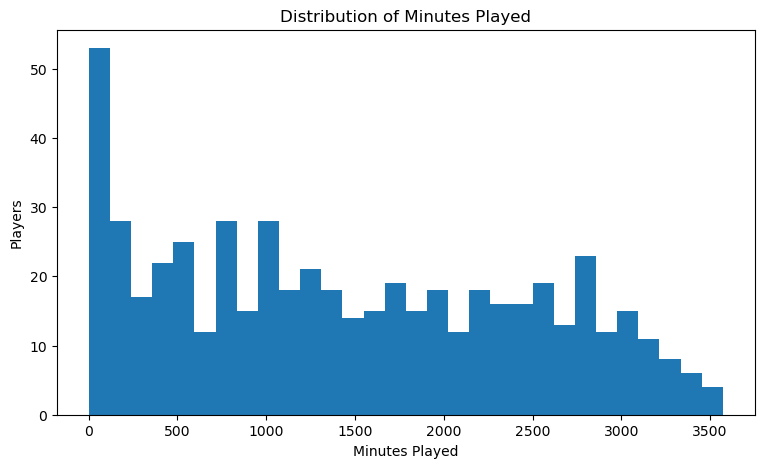

In [8]:
plt.figure(figsize=(9, 5))

plt.hist(df["minutes_played"], bins=30)

plt.xlabel("Minutes Played")
plt.ylabel("Players")
plt.title("Distribution of Minutes Played")

plt.show()

In [9]:
thresholds = [0, 90, 180, 450, 630, 900, 1350, 1800]

threshold_summary = pd.DataFrame({
    "min_minutes": thresholds,
    "players_remaining": [
        (df["minutes_played"] >= x).sum()
        for x in thresholds
    ]
})

threshold_summary["pct_remaining"] = (
    threshold_summary["players_remaining"] / len(df) * 100
)

threshold_summary

,min_minutes,players_remaining,pct_remaining
0,0,539,100.000000
1,90,505,93.692022
2,180,475,88.126160
3,450,423,78.478664
4,630,392,72.727273
5,900,343,63.636364
6,1350,264,48.979592
7,1800,202,37.476809


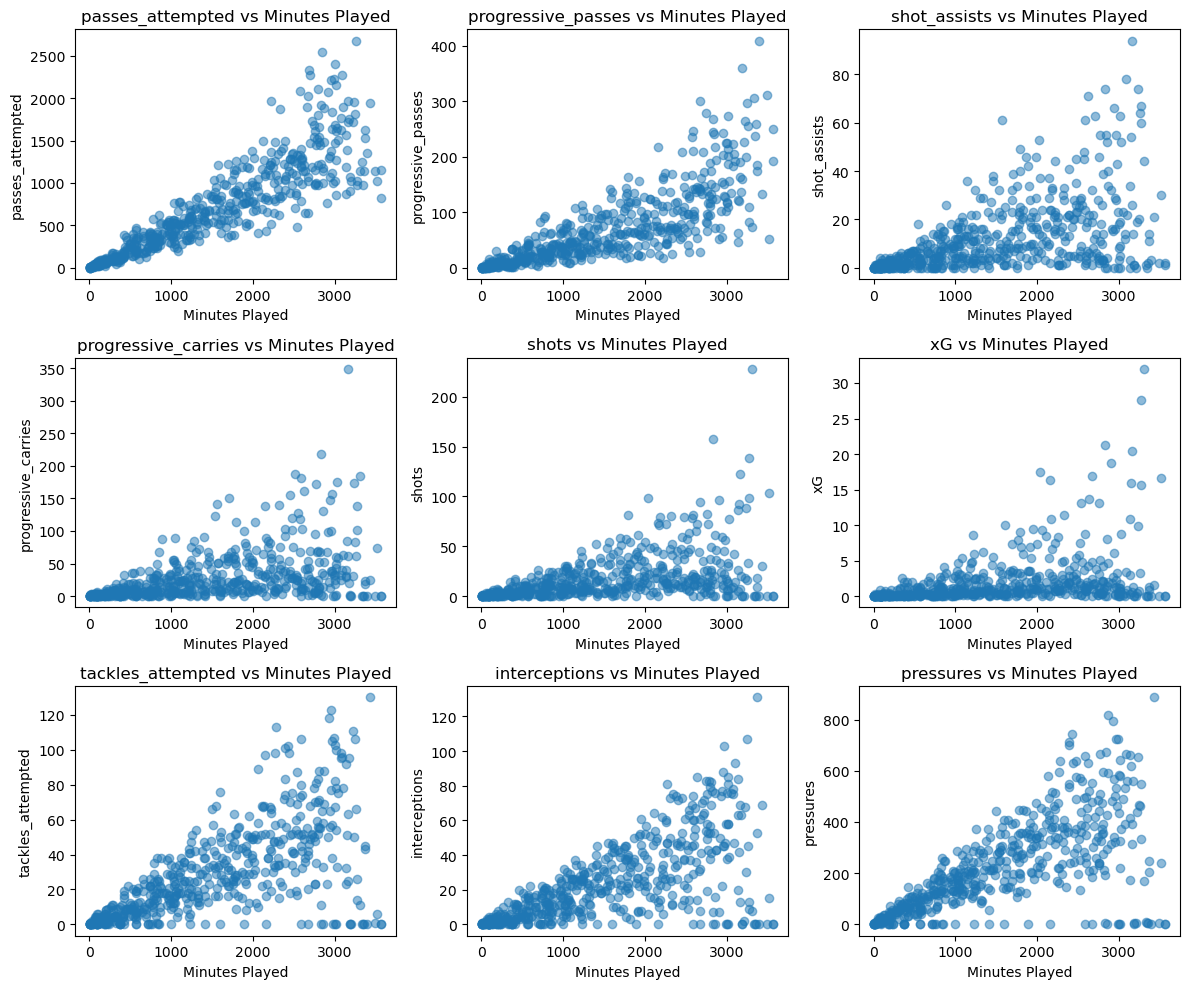

In [10]:
metrics = [
    "passes_attempted",
    "progressive_passes",
    "shot_assists",
    "progressive_carries",
    "shots",
    "xG",
    "tackles_attempted",
    "interceptions",
    "pressures",
]

fig, axes = plt.subplots(
    3, 3,
    figsize=(12, 10)
)

axes = axes.flatten()

for ax, metric in zip(axes, metrics):
    ax.scatter(
        df["minutes_played"],
        df[metric],
        alpha=0.5
    )

    ax.set_xlabel("Minutes Played")
    ax.set_ylabel(metric)
    ax.set_title(f"{metric} vs Minutes Played")

plt.tight_layout()
plt.show()

### Creating exploratory per-90 metrics ###

In [11]:
eda_df = df.copy()

for col in volume_cols:
    eda_df[f"{col}_per90"] = np.where(
        eda_df["minutes_played"] > 0,
        eda_df[col] / eda_df["minutes_played"] * 90,
        np.nan
    )

In [12]:
eda_df.nlargest(
    15,
    "shots_per90"
)[
    [
        "player",
        "teams",
        "minutes_played",
        "shots",
        "shots_per90",
    ]
]

,player,teams,minutes_played,shots,shots_per90
522,Eneko Capilla González,[Real Sociedad],10.087367,1.0,8.922051
39,Cristiano Ronaldo dos Santos Aveiro,[Real Madrid],3308.513000,228.0,6.202182
519,Ian González Nieto,[Getafe],17.169917,1.0,5.241726
53,Lionel Andrés Messi Cuccittini,[Barcelona],2831.425350,158.0,5.022206
321,Miguel Filipe Nunes Cardoso,[RC Deportivo La Coruña],55.481700,3.0,4.866469
365,Karim Benzema,[Real Madrid],2037.680650,98.0,4.328451
100,Gareth Frank Bale,[Real Madrid],1794.240983,81.0,4.062999
526,Leandro Damião da Silva dos Santos,[Real Betis],138.875083,6.0,3.888387
44,Luis Alberto Suárez Díaz,[Barcelona],3273.202867,139.0,3.821945
450,David Barral Torres,[Granada],405.969100,17.0,3.768760


In [13]:
eda_df.nlargest(
    15,
    "goals_per90"
)[
    [
        "player",
        "teams",
        "minutes_played",
        "goals",
        "goals_per90",
    ]
]

,player,teams,minutes_played,goals,goals_per90
534,Mikel Arruabarrena Aranbide,[Eibar],77.516467,1.0,1.161044
44,Luis Alberto Suárez Díaz,[Barcelona],3273.202867,40.0,1.099840
365,Karim Benzema,[Real Madrid],2037.680650,24.0,1.060029
157,Imanol Agirretxe Arruti,[Real Sociedad],1216.227750,13.0,0.961991
100,Gareth Frank Bale,[Real Madrid],1794.240983,19.0,0.953049
39,Cristiano Ronaldo dos Santos Aveiro,[Real Madrid],3308.513000,35.0,0.952089
53,Lionel Andrés Messi Cuccittini,[Barcelona],2831.425350,26.0,0.826439
195,Diego González Polanco,[Sevilla],115.706867,1.0,0.777828
260,Jon Bautista Orgilles,[Real Sociedad],124.473400,1.0,0.723046
20,Neymar da Silva Santos Junior,[Barcelona],3163.648833,24.0,0.682756


In [14]:
eda_df.nlargest(
    15,
    "progressive_passes_per90"
)[
    [
        "player",
        "teams",
        "minutes_played",
        "progressive_passes",
        "progressive_passes_per90",
    ]
]

,player,teams,minutes_played,progressive_passes,progressive_passes_per90
145,Iago Herrerín Buisán,[Athletic Club],181.047333,30.0,14.913227
489,Jesús Fernández Collado,[Granada],97.215967,15.0,13.886608
532,Ander Gayoso Reina,[Eibar],8.075533,1.0,11.144775
111,Gorka Iraizoz Moreno,[Athletic Club],3397.077250,409.0,10.835785
316,Răzvan Dincă Raț,[Rayo Vallecano],773.545000,93.0,10.820314
6,Mathew Ryan,[Valencia],762.405733,89.0,10.506217
508,Manuel Fernández Muñíz,[RC Deportivo La Coruña],713.279267,83.0,10.472756
494,Germán Darío Lux,[RC Deportivo La Coruña],2672.526917,301.0,10.136474
319,Asier Riesgo Unamuno,[Eibar],3191.239283,359.0,10.124593
485,Nikolaos Karabelas,[Levante UD],93.239383,10.0,9.652573


### Exploring figures after filtering ###

In [15]:
MIN_MINUTES = 600

model_pool = eda_df[
    eda_df["minutes_played"] >= MIN_MINUTES
].copy()

In [16]:
model_pool["position_group"].value_counts()

position_group
Outside Midfielder      81
Fullback                75
Center Midfielder       75
Center Back             67
Forward                 50
Goalkeeper              29
Attacking Midfielder    17
Name: count, dtype: int64

In [17]:
model_pool.nlargest(
    15,
    "goals_per90"
)[
    [
        "player",
        "teams",
        "minutes_played",
        "goals",
        "goals_per90",
    ]
]

,player,teams,minutes_played,goals,goals_per90
44,Luis Alberto Suárez Díaz,[Barcelona],3273.202867,40.0,1.099840
365,Karim Benzema,[Real Madrid],2037.680650,24.0,1.060029
157,Imanol Agirretxe Arruti,[Real Sociedad],1216.227750,13.0,0.961991
100,Gareth Frank Bale,[Real Madrid],1794.240983,19.0,0.953049
39,Cristiano Ronaldo dos Santos Aveiro,[Real Madrid],3308.513000,35.0,0.952089
53,Lionel Andrés Messi Cuccittini,[Barcelona],2831.425350,26.0,0.826439
20,Neymar da Silva Santos Junior,[Barcelona],3163.648833,24.0,0.682756
102,Kevin Gameiro,[Sevilla],2158.572567,16.0,0.667108
52,Antoine Griezmann,[Atlético Madrid],3150.329200,22.0,0.628506
98,Aritz Aduriz Zubeldia,[Athletic Club],2902.135867,20.0,0.620233


In [18]:
model_pool.nlargest(
    15,
    "progressive_passes_per90"
)[
    [
        "player",
        "teams",
        "minutes_played",
        "progressive_passes",
        "progressive_passes_per90",
    ]
]

,player,teams,minutes_played,progressive_passes,progressive_passes_per90
111,Gorka Iraizoz Moreno,[Athletic Club],3397.077250,409.0,10.835785
316,Răzvan Dincă Raț,[Rayo Vallecano],773.545000,93.0,10.820314
6,Mathew Ryan,[Valencia],762.405733,89.0,10.506217
508,Manuel Fernández Muñíz,[RC Deportivo La Coruña],713.279267,83.0,10.472756
494,Germán Darío Lux,[RC Deportivo La Coruña],2672.526917,301.0,10.136474
319,Asier Riesgo Unamuno,[Eibar],3191.239283,359.0,10.124593
135,Damián Nicolás Suárez Suárez,[Getafe],2748.081450,279.0,9.137284
392,Diego Mariño Villar,[Levante UD],2161.458400,218.0,9.077205
178,Manuel Agudo Durán,[Celta Vigo],2587.228000,247.0,8.592208
53,Lionel Andrés Messi Cuccittini,[Barcelona],2831.425350,268.0,8.518678


## Exploring feature distribution ##

### Raw volume distributions ###

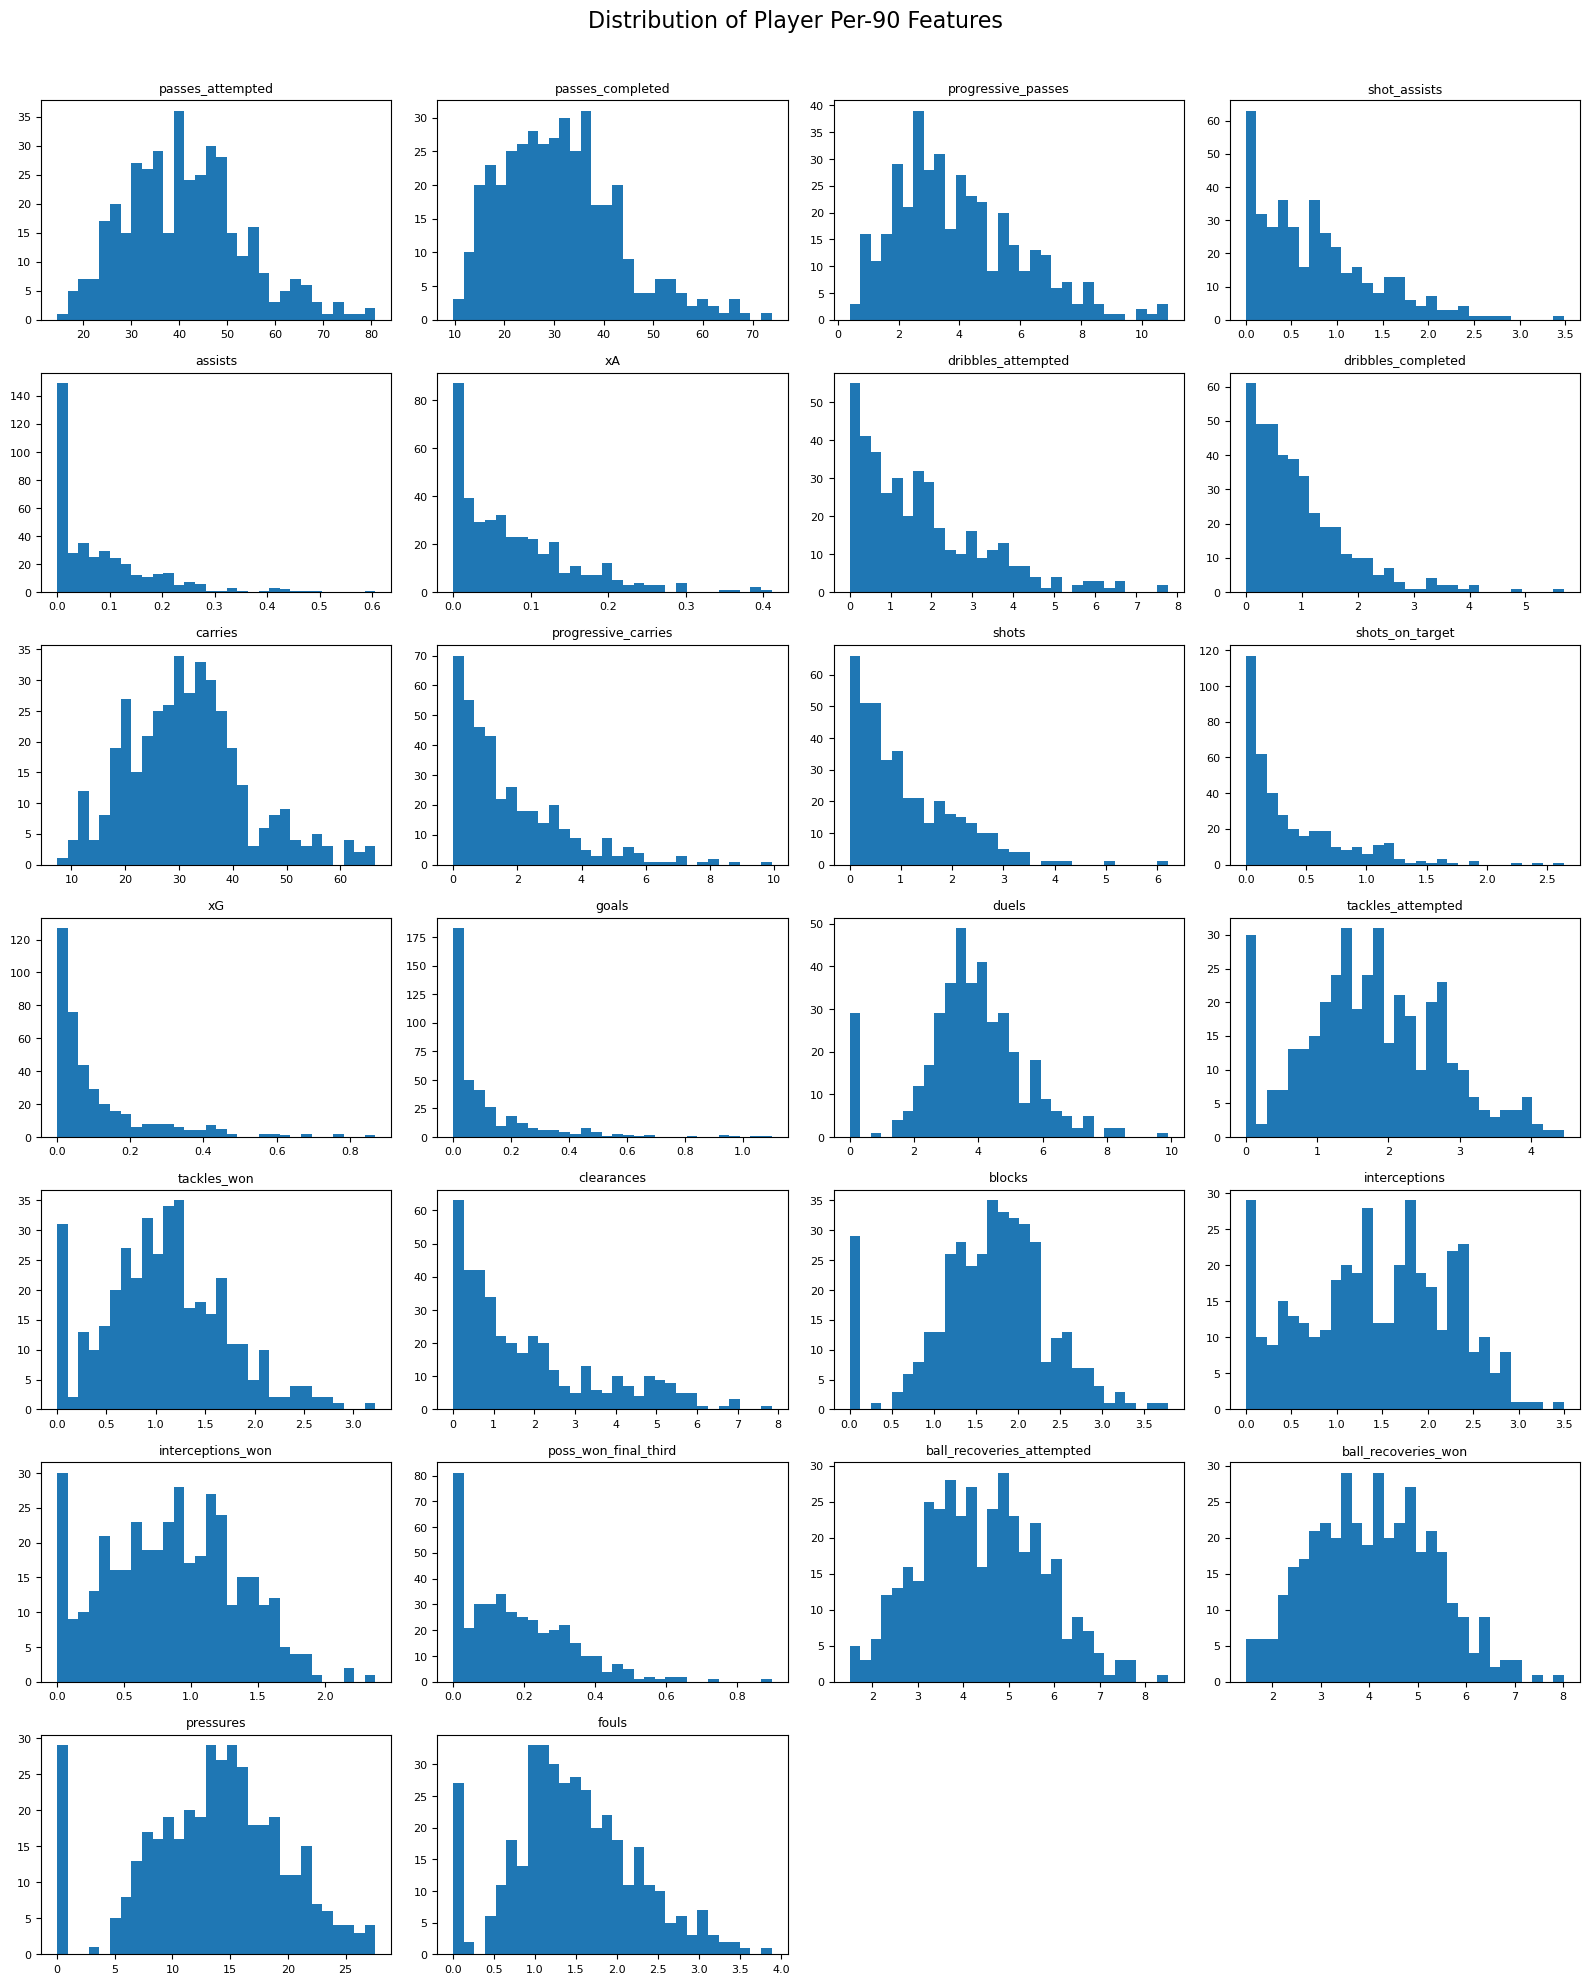

In [19]:
import math
import matplotlib.pyplot as plt

per90_cols = [
    f"{col}_per90"
    for col in volume_cols
]

n_cols = 4
n_rows = math.ceil(len(per90_cols) / n_cols)

fig, axes = plt.subplots(
    n_rows,
    n_cols,
    figsize=(16, 2.8 * n_rows)
)

axes = axes.flatten()

for ax, col in zip(axes, per90_cols):
    ax.hist(model_pool[col].dropna(), bins=30)
    ax.set_title(col.replace("_per90", ""), fontsize=9)
    ax.tick_params(labelsize=8)

for ax in axes[len(per90_cols):]:
    ax.remove()

fig.suptitle(
    "Distribution of Player Per-90 Features",
    fontsize=16,
    y=1.01
)

plt.tight_layout()
plt.show()

### Sparsity ###

In [41]:
per90_sparsity = pd.DataFrame({
    "zero_pct": (
        model_pool[per90_cols]
        .eq(0)
        .mean()
        * 100
    ),
    "mean": model_pool[per90_cols].mean(),
    "std": model_pool[per90_cols].std(),
})

per90_sparsity.sort_values(
    "zero_pct",
    ascending=False
)

,zero_pct,mean,std
assists_per90,42.531646,0.074165,0.095867
goals_per90,36.708861,0.114133,0.149596
poss_won_final_third_per90,25.316456,0.158630,0.155468
shots_on_target_per90,16.202532,0.373336,0.391484
interceptions_won_per90,8.860759,0.621035,0.439053
tackles_won_per90,8.607595,1.043354,0.651982
shots_per90,8.607595,1.141017,0.961583
xG_per90,8.607595,0.111815,0.125554
interceptions_per90,8.354430,0.994601,0.681389
tackles_attempted_per90,8.101266,1.744149,1.017929


### Efficiency feature distributions ###

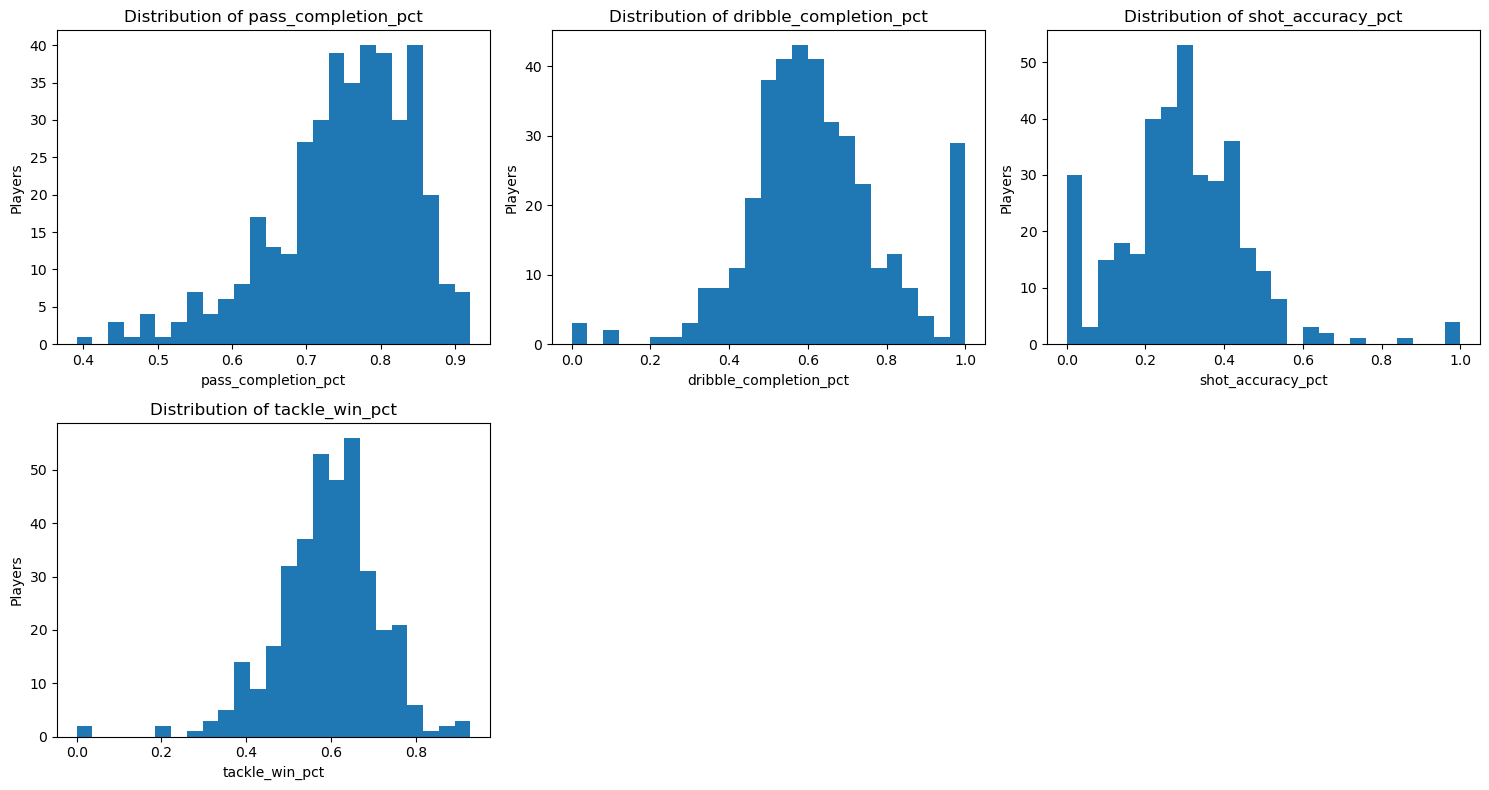

In [43]:
n_cols = 3
n_rows = math.ceil(len(rate_cols) / n_cols)

fig, axes = plt.subplots(
    n_rows,
    n_cols,
    figsize=(15, 4 * n_rows)
)

axes = axes.flatten()

for ax, col in zip(axes, rate_cols):
    ax.hist(
        model_pool[col].dropna(),
        bins=25
    )

    ax.set_xlabel(col)
    ax.set_ylabel("Players")
    ax.set_title(f"Distribution of {col}")

# Hide unused plots
for ax in axes[len(rate_cols):]:
    ax.set_visible(False)

plt.tight_layout()
plt.show()

In [45]:
print(f"\n--- pass_completion_pct ---")

display(
    model_pool.nlargest(
        10,
        "pass_completion_pct"
    )[
        [
            "player",
            "teams",
            "minutes_played",
            "passes_attempted",
            "passes_completed",
            "pass_completion_pct"
        ]
    ]
)

print(f"\n--- dribble_completion_pct ---")

display(
    model_pool.nlargest(
        10,
        "dribble_completion_pct"
    )[
        [
            "player",
            "teams",
            "minutes_played",
            "dribbles_attempted",
            "dribbles_completed",
            "dribble_completion_pct"
        ]
    ]
)

print(f"\n--- shot_accuracy_pct ---")

display(
    model_pool.nlargest(
        10,
        "shot_accuracy_pct"
    )[
        [
            "player",
            "teams",
            "minutes_played",
            "shots",
            "shots_on_target",
            "shot_accuracy_pct"
        ]
    ]
)

print(f"\n--- tackle_win_pct ---")

display(
    model_pool.nlargest(
        10,
        "tackle_win_pct"
    )[
        [
            "player",
            "teams",
            "minutes_played",
            "tackles_attempted",
            "tackles_won",
            "tackle_win_pct"
        ]
    ]
)


--- pass_completion_pct ---


,player,teams,minutes_played,passes_attempted,passes_completed,pass_completion_pct
156,Mohamed Naser Elsayed Elneny,[Arsenal],837.883983,744.0,685.0,0.920699
465,John Terry,[Chelsea],2142.627717,933.0,853.0,0.914255
463,Samir Nasri,[Manchester City],583.395167,437.0,398.0,0.910755
332,Gabriel Armando de Abreu,[Arsenal],1874.097633,1074.0,978.0,0.910615
310,John Michael Nchekwube Obinna,[Chelsea],1931.694283,1226.0,1115.0,0.909462
172,Sung-Yeung Ki,[Swansea City],1981.161550,1189.0,1074.0,0.903280
116,Per Mertesacker,[Arsenal],2175.750150,1238.0,1116.0,0.901454
177,Kevin Wimmer,[Tottenham Hotspur],866.536417,543.0,487.0,0.896869
3,Mousa Sidi Yaya Dembélé,[Tottenham Hotspur],2395.125417,1383.0,1238.0,0.895155
95,Francis Joseph Coquelin,[Arsenal],1744.072600,1104.0,988.0,0.894928



--- dribble_completion_pct ---


,player,teams,minutes_played,dribbles_attempted,dribbles_completed,dribble_completion_pct
14,Paul Dummett,[Newcastle United],2017.515600,6.0,6.0,1.0
16,Jan Vertonghen,[Tottenham Hotspur],2761.582983,10.0,10.0,1.0
50,Joe Hart,[Manchester City],3314.769400,1.0,1.0,1.0
105,Petr Čech,[Arsenal],3259.078433,2.0,2.0,1.0
116,Per Mertesacker,[Arsenal],2175.750150,2.0,2.0,1.0
122,Mamadou Sakho,[Liverpool],1989.493133,3.0,3.0,1.0
150,Jack Butland,[Stoke City],2991.395767,1.0,1.0,1.0
152,Simon Mignolet,[Liverpool],3283.115800,4.0,4.0,1.0
166,Gareth McAuley,[West Bromwich Albion],3275.548133,8.0,8.0,1.0
182,Adrián San Miguel del Castillo,[West Ham United],3098.982633,1.0,1.0,1.0



--- shot_accuracy_pct ---


,player,teams,minutes_played,shots,shots_on_target,shot_accuracy_pct
17,Jamaal Lascelles,[Newcastle United],1244.191483,4.0,4.0,1.000000
55,Maya Yoshida,[Southampton],1119.037183,2.0,2.0,1.000000
87,Luke Shaw,[Manchester United],475.492617,1.0,1.0,1.000000
400,Cameron Borthwick-Jackson,[Manchester United],749.376700,1.0,1.0,1.000000
158,Martin Olsson,[Norwich City],1914.403867,7.0,6.0,0.857143
496,Aly Cissokho,[Aston Villa],1699.615767,4.0,3.0,0.750000
163,Rhu-endly Martina,[Southampton],1165.276850,3.0,2.0,0.666667
219,Gerard Deulofeu Lázaro,[Everton],1483.711217,12.0,8.0,0.666667
236,Aaron Lennon,[Everton],1653.358867,18.0,11.0,0.611111
62,Tom Carroll,[Tottenham Hotspur],577.208650,5.0,3.0,0.600000



--- tackle_win_pct ---


,player,teams,minutes_played,tackles_attempted,tackles_won,tackle_win_pct
219,Gerard Deulofeu Lázaro,[Everton],1483.711217,14.0,13.0,0.928571
416,Santiago Cazorla González,[Arsenal],1364.026183,25.0,23.0,0.920000
35,Sergio Leonel Agüero del Castillo,[Manchester City],2482.926667,22.0,20.0,0.909091
241,Diafra Sakho,[West Ham United],1619.270900,15.0,13.0,0.866667
268,Gilbert Gianelli Imbula Wanga,[Stoke City],1352.281900,15.0,13.0,0.866667
483,Mario Suárez Mata,[Watford],809.579033,12.0,10.0,0.833333
418,Kevin Linford Stewart,[Liverpool],598.085317,21.0,17.0,0.809524
208,José Leonardo Ulloa,[Leicester City],1089.399017,26.0,21.0,0.807692
193,Alex Iwobi,[Arsenal],661.235083,10.0,8.0,0.800000
330,Jordi Amat Maas,[Swansea City],499.227550,5.0,4.0,0.800000


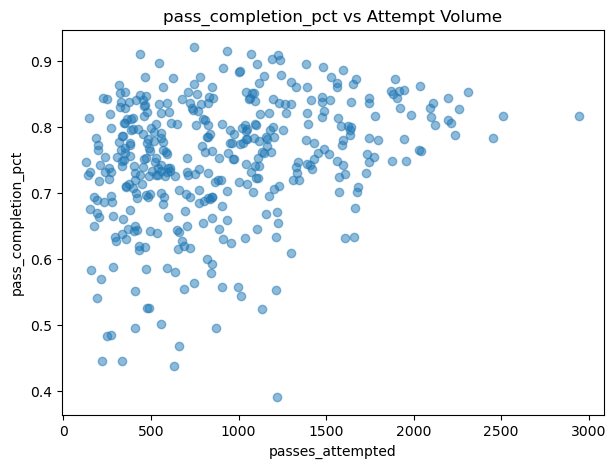

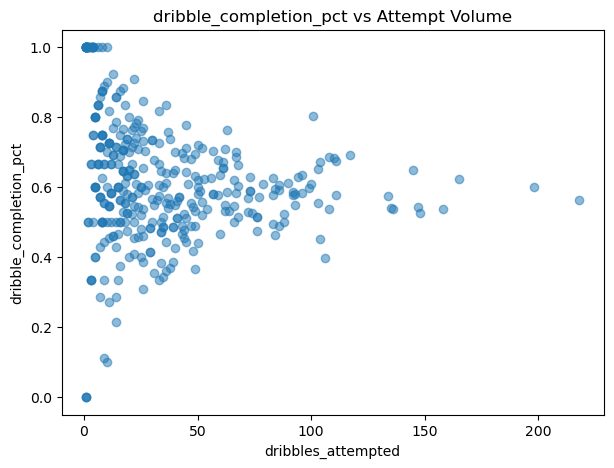

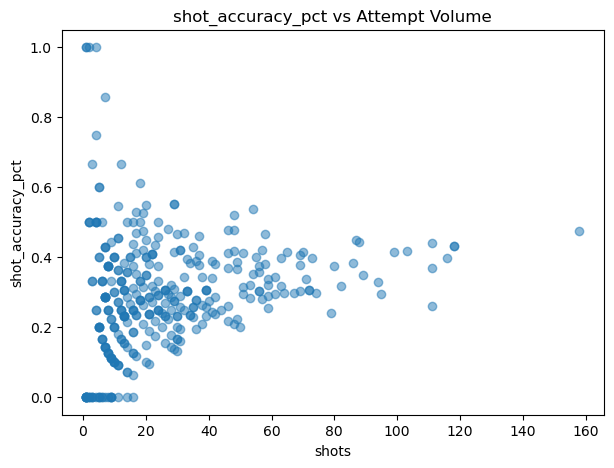

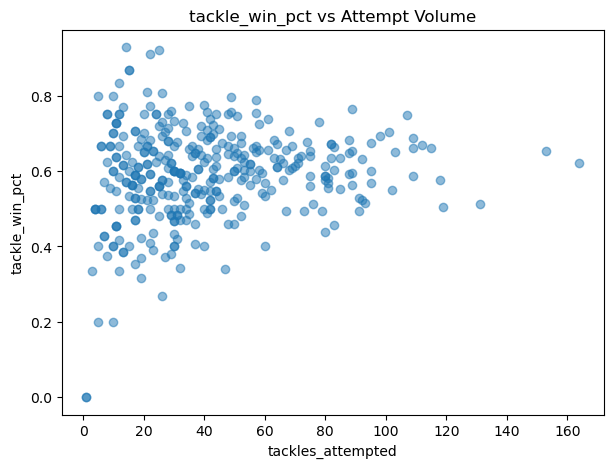

In [47]:
rate_attempt_pairs = [
    ("pass_completion_pct", "passes_attempted"),
    ("dribble_completion_pct", "dribbles_attempted"),
    ("shot_accuracy_pct", "shots"),
    ("tackle_win_pct", "tackles_attempted"),
]

for pct, attempts in rate_attempt_pairs:
    plt.figure(figsize=(7, 5))

    plt.scatter(
        model_pool[attempts],
        model_pool[pct],
        alpha=0.5
    )

    plt.xlabel(attempts)
    plt.ylabel(pct)
    plt.title(f"{pct} vs Attempt Volume")

    plt.show()

### Over/Under performance feature distributions ###

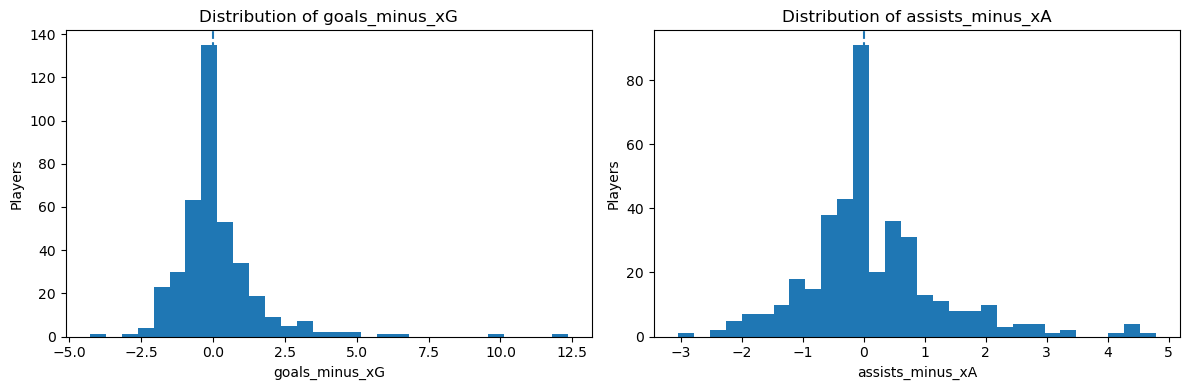

In [20]:
fig, axes = plt.subplots(
    1,
    len(performance_cols),
    figsize=(6 * len(performance_cols), 4)
)

for ax, col in zip(axes, performance_cols):
    ax.hist(
        model_pool[col].dropna(),
        bins=30
    )

    ax.axvline(0, linestyle="--")

    ax.set_xlabel(col)
    ax.set_ylabel("Players")
    ax.set_title(f"Distribution of {col}")

plt.tight_layout()
plt.show()

In [21]:
model_pool.nlargest(
    10,
    "goals_minus_xG"
)[
    ["player", "minutes_played", "goals", "xG", "goals_minus_xG"]
]

,player,minutes_played,goals,xG,goals_minus_xG
44,Luis Alberto Suárez Díaz,3273.202867,40.0,27.648656,12.351344
100,Gareth Frank Bale,1794.240983,19.0,8.988328,10.011672
365,Karim Benzema,2037.680650,24.0,17.413095,6.586905
52,Antoine Griezmann,3150.329200,22.0,15.968187,6.031813
69,James David Rodríguez Rubio,1574.364050,7.0,2.219939,4.780061
53,Lionel Andrés Messi Cuccittini,2831.425350,26.0,21.263604,4.736396
97,Iñaki Williams Arthuer,1666.243583,8.0,3.483108,4.516892
157,Imanol Agirretxe Arruti,1216.227750,13.0,8.565384,4.434616
244,Jozabed Sánchez Ruiz,2151.568217,9.0,5.369730,3.630270
20,Neymar da Silva Santos Junior,3163.648833,24.0,20.472623,3.527377


In [22]:
model_pool.nsmallest(
    10,
    "goals_minus_xG"
)[
    ["player", "minutes_played", "goals", "xG", "goals_minus_xG"]
]

,player,minutes_played,goals,xG,goals_minus_xG
403,Álvaro Vázquez García,2063.902517,5.0,9.287005,-4.287005
58,Carlos Alberto Vela Garrido,2851.938017,5.0,8.068022,-3.068022
70,Rodrigo Moreno Machado,1445.599217,2.0,4.371011,-2.371011
9,Nordin Amrabat,1028.951583,0.0,2.352098,-2.352098
223,Daniel Wass,2805.612317,2.0,4.258136,-2.258136
80,Michael Krohn-Dehli,1753.543100,1.0,3.183176,-2.183176
132,Jorge Franco Alviz,1051.121133,1.0,3.053654,-2.053654
45,Diego Roberto Godín Leal,2761.883867,1.0,3.036825,-2.036825
71,Marco Asensio Willemsen,2941.299817,4.0,6.018848,-2.018848
259,Rubén Pardo Gutiérrez,1863.862617,0.0,1.919103,-1.919103


## Investigating Correlation ##

In [26]:
candidate_features = (
    per90_cols
    + rate_cols
    + performance_cols
)

corr = model_pool[candidate_features].corr()

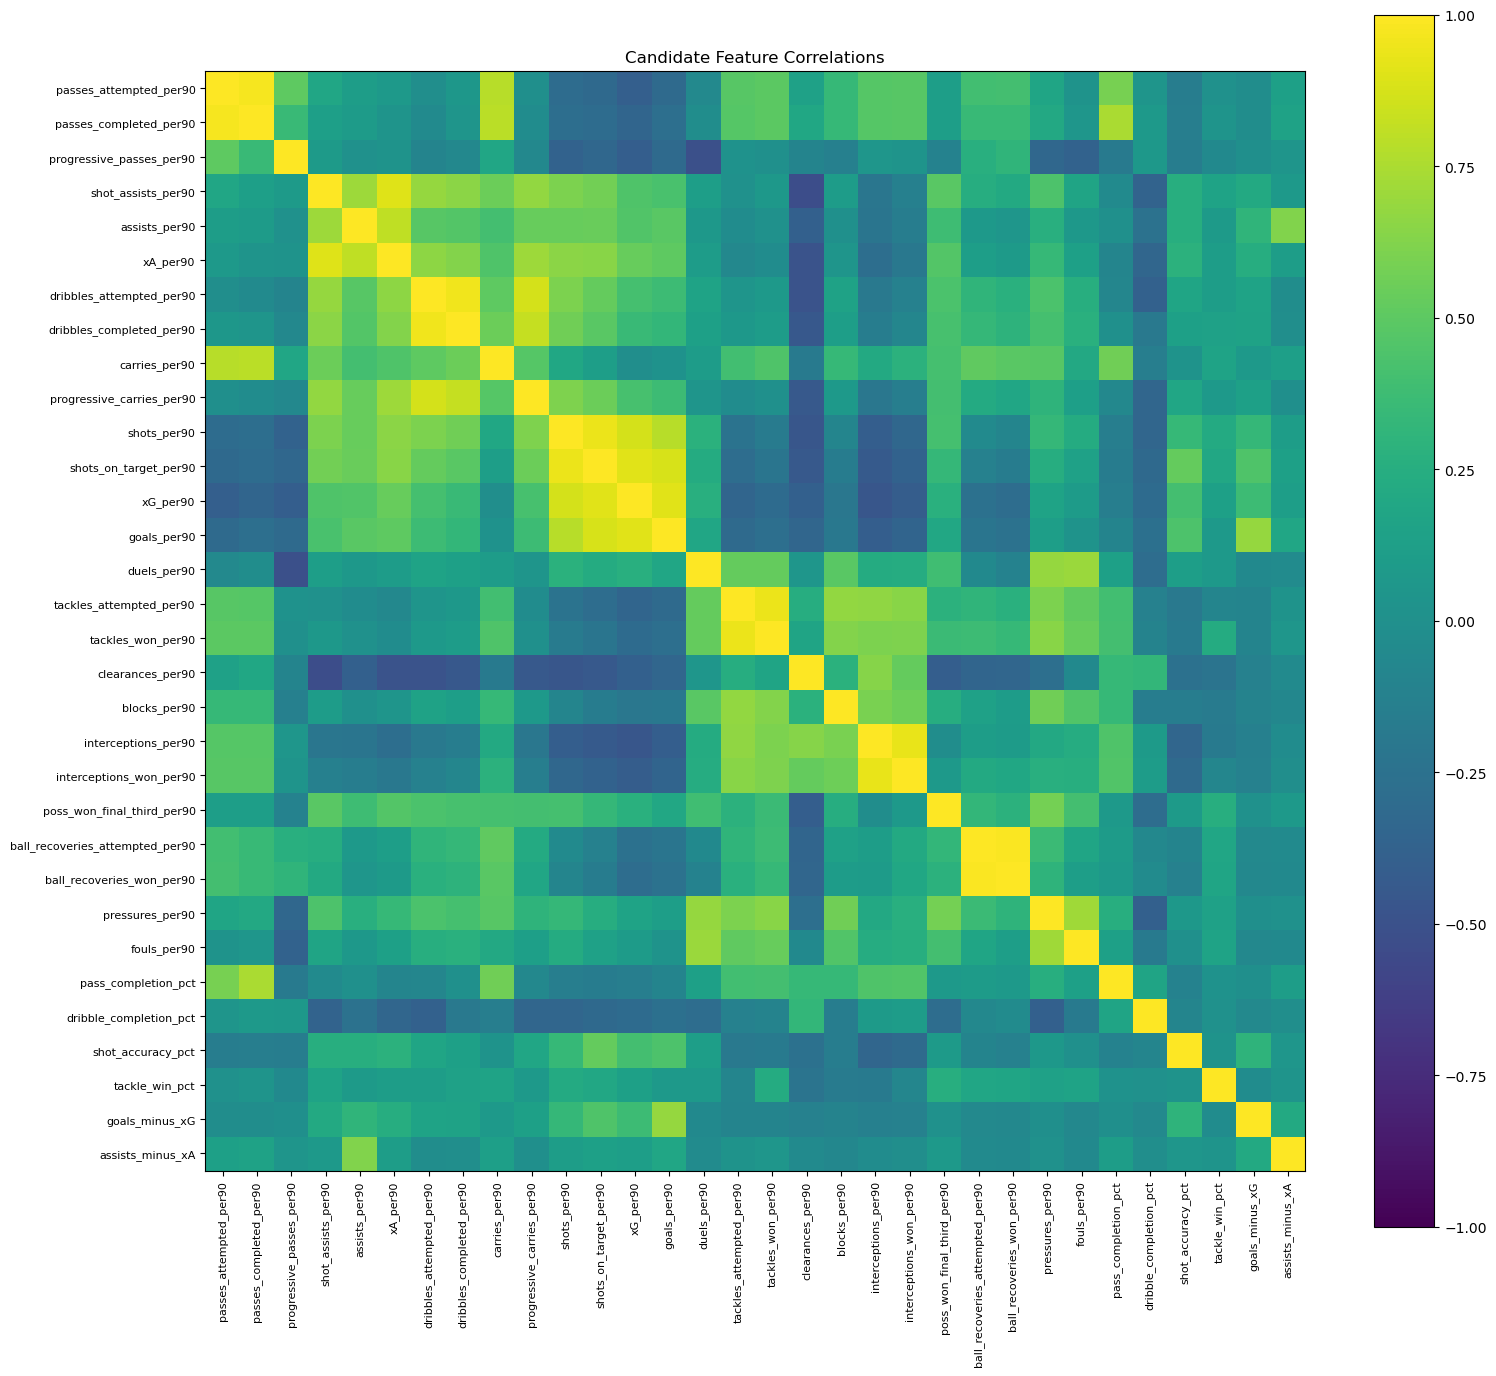

In [27]:
fig, ax = plt.subplots(figsize=(16, 14))

im = ax.imshow(
    corr,
    vmin=-1,
    vmax=1
)

ax.set_xticks(range(len(corr.columns)))
ax.set_yticks(range(len(corr.columns)))

ax.set_xticklabels(
    corr.columns,
    rotation=90,
    fontsize=8
)

ax.set_yticklabels(
    corr.columns,
    fontsize=8
)

fig.colorbar(im)

plt.title("Candidate Feature Correlations")
plt.tight_layout()
plt.show()

In [54]:
upper_triangle = corr.where(
    np.triu(
        np.ones(corr.shape),
        k=1
    ).astype(bool)
)

correlation_pairs = (
    upper_triangle
    .stack()
    .reset_index()
)

correlation_pairs.columns = [
    "feature_1",
    "feature_2",
    "correlation",
]

correlation_pairs["abs_correlation"] = (
    correlation_pairs["correlation"].abs()
)

correlation_pairs.sort_values(
    "abs_correlation",
    ascending=False
).head(25)

,feature_1,feature_2,correlation,abs_correlation
451,ball_recoveries_attempted_per90,ball_recoveries_won_per90,0.990186,0.990186
0,passes_attempted_per90,passes_completed_per90,0.971473,0.971473
171,dribbles_attempted_per90,dribbles_completed_per90,0.965447,0.965447
360,tackles_attempted_per90,tackles_won_per90,0.952651,0.952651
418,interceptions_per90,interceptions_won_per90,0.950987,0.950987
265,shots_per90,shots_on_target_per90,0.930198,0.930198
91,shot_assists_per90,xA_per90,0.919749,0.919749
286,shots_on_target_per90,xG_per90,0.890064,0.890064
287,shots_on_target_per90,goals_per90,0.888338,0.888338
306,xG_per90,goals_per90,0.883990,0.883990


## Examining major player profiles ##

In [28]:
def player_profile(name):
    mask = model_pool["player"].str.contains(
        name,
        case=False,
        na=False
    )

    player_row = model_pool.loc[mask].iloc[0]

    profile = pd.DataFrame({
        "Player": player_row[candidate_features],
        "League Average": model_pool[candidate_features].mean()
    })

    print(f"Player: {player_row['player']}")
    print(f"Team(s): {player_row['teams']}")
    print(f"Minutes: {player_row['minutes_played']:.0f}")

    return profile

In [30]:
player_profile("Ronaldo")

Player: Cristiano Ronaldo dos Santos Aveiro
Team(s): ['Real Madrid']
Minutes: 3309


,Player,League Average
passes_attempted_per90,31.174126,41.280873
passes_completed_per90,23.883841,31.215538
progressive_passes_per90,2.012989,3.994238
shot_assists_per90,1.196912,0.760644
assists_per90,0.272026,0.082536
xA_per90,0.154695,0.079005
dribbles_attempted_per90,2.584243,1.742558
dribbles_completed_per90,1.468938,0.962897
carries_per90,30.521264,31.582035
progressive_carries_per90,5.032472,1.759501


In [31]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.max_columns", 100)

PROJECT_DIR = Path.cwd().parent
DATA_DIR = PROJECT_DIR / "data" / "processed"

competition = "La Liga"
season = "2015-2016"

positions_path = DATA_DIR / competition / season / "player_positions.parquet"

player_positions = pd.read_parquet(positions_path)

print(player_positions.shape)
player_positions.head(25)

(539, 5)


,player_id,player,season,primary_position,position_group
0,3023,Yuri Berchiche Izeta,2015-2016,Left Back,Fullback
1,3063,Danilo Luiz da Silva,2015-2016,Right Back,Fullback
2,3084,Christian Atsu Twasam,2015-2016,Right Midfield,Outside Midfielder
3,3130,Gaël Kakuta,2015-2016,Left Midfield,Outside Midfielder
4,3160,Rene Krhin,2015-2016,Right Defensive Midfield,Center Midfielder
5,3236,Sergi Darder Moll,2015-2016,Left Defensive Midfield,Center Midfielder
6,3240,Mathew Ryan,2015-2016,Goalkeeper,Goalkeeper
7,3253,Adil Rami,2015-2016,Right Center Back,Center Back
8,3292,Abdoulaye Doucouré,2015-2016,Left Defensive Midfield,Center Midfielder
9,3302,Nordin Amrabat,2015-2016,Right Center Forward,Forward


In [5]:
player_positions[player_positions["primary_position"].isin(["Left Midfield", "Right Midfield"])]

,player_id,player,season,primary_position,position_group
1,2966,Stéphane Sessègnon,2015-2016,Right Midfield,Midfielder
7,3049,Matt Ritchie,2015-2016,Right Midfield,Midfielder
32,3196,Wahbi Khazri,2015-2016,Left Midfield,Midfielder
46,3286,Nathan Redmond,2015-2016,Right Midfield,Midfielder
56,3302,Nordin Amrabat,2015-2016,Left Midfield,Midfielder
59,3307,Marc Albrighton,2015-2016,Left Midfield,Midfielder
64,3312,Demarai Gray,2015-2016,Right Midfield,Midfielder
107,3463,Junior Stanislas,2015-2016,Left Midfield,Midfielder
133,3507,Wilfried Zaha,2015-2016,Right Midfield,Midfielder
136,3514,James McClean,2015-2016,Left Midfield,Midfielder


In [13]:
pd.set_option("display.max_rows", 110)

player_positions[player_positions["primary_position"].isin(["Left Wing", "Right Wing", "Left Midfield", "Right Midfield"])]

,player_id,player,season,primary_position,position_group
1,2966,Stéphane Sessègnon,2015-2016,Right Midfield,Midfielder
2,2988,Memphis Depay,2015-2016,Left Wing,Winger
5,3043,Christian Dannemann Eriksen,2015-2016,Left Wing,Winger
7,3049,Matt Ritchie,2015-2016,Right Midfield,Midfielder
15,3076,Ayoze Pérez Gutiérrez,2015-2016,Left Wing,Winger
18,3083,Heung-Min Son,2015-2016,Right Wing,Winger
22,3089,Kevin De Bruyne,2015-2016,Right Wing,Winger
24,3091,Moussa Sissoko,2015-2016,Right Wing,Winger
32,3196,Wahbi Khazri,2015-2016,Left Midfield,Midfielder
34,3233,Raheem Sterling,2015-2016,Left Wing,Winger
